# BHSM Blackhole Tracker: native unresolved photometry

The released OGLE-III measurements contain unresolved apparent magnitudes, not resolved image pairs. This route preserves their native times, published errors and original row identities. It fits one effective optical configuration with the explicit BHSM interpretation **one potential counted once**. A timescale is not a black-hole mass.

Install the matching wheel first. Set `BHSM_DATA_ROOT` to the extracted handoff's `data` directory to use the actual OGLE3-ULENS-0585 observations. Original data stay outside the software repository. With no data location, this notebook uses a clearly labelled independent synthetic PSPL injection, so the software tutorial remains portable. The complete measured 100-event analysis is separately frozen and includes all failures; this walkthrough is not a new selection or discovery claim.

In [1]:
import os
from pathlib import Path
import numpy as np
from bhtracker.observations import load_ogle_photometry, parse_ogle_photometry
from bhtracker.photometry import fit_photometry, profile_timescale
from bhtracker.report import export_analysis_bundle, replay_analysis

location = os.environ.get('BHSM_DATA_ROOT')
if location:
    import json
    selected = json.loads((Path(location) / 'pilot_selection.json').read_text(encoding='utf8'))
    entry = next(row for row in selected['selected'] if row['event_id'] == 'OGLE3-ULENS-0585')
    dataset = load_ogle_photometry(Path(location) / entry['relative_path'], metadata={'event_id': entry['event_id']})
    input_kind = 'ACTUAL DOWNLOADED OGLE-III observations; historical event, mass unresolved'
else:
    t = np.linspace(1000, 1900, 180)
    u2 = .28**2 + ((t - 1375) / 72)**2
    A = (u2 + 2) / np.sqrt(u2 * (u2 + 4))
    mag = 18 - 2.5 * np.log10(1 + .65 * (A - 1))
    raw = '\n'.join(f'{a:.9f} {b:.12f} .008' for a, b in zip(t, mag)).encode('ascii')
    dataset = parse_ogle_photometry(raw, source_name='SYNTHETIC.dat', metadata={'synthetic': True})
    input_kind = 'SYNTHETIC independent analytic injection; no measured event'
print(input_kind)
print({'rows': len(dataset.rows), 'sha256': dataset.sha256,
       'native_time_and_calibration': dataset.document['instruments']})

ACTUAL DOWNLOADED OGLE-III observations; historical event, mass unresolved
{'rows': 734, 'sha256': 'ab8c2f10f29a945b52b8b4185f9c20909b6a041e0ddb4dd3432dc9f097eb63e3', 'native_time_and_calibration': {'OGLE-III': {'filter': 'I', 'time': {'reference': 'HJD', 'numeric_origin_jd': 2450000.0, 'clock_scale': 'UNSPECIFIED', 'unit': 'day'}, 'magnitude_convention': 'published OGLE I apparent magnitude', 'calibration': 'OGLE-III class-A optimized reduction; published error corrections already applied', 'error_treatment': 'native positive magnitude errors unchanged; diagonal independence is an analysis assumption'}}}


## Fit every numeric row

The likelihood is Gaussian in native magnitude with the published errors and an explicitly assumed independent diagonal noise model. No clipping, thinning, fabricated covariance or repeated OGLE error correction is performed. The default source and blend fluxes are nonnegative. Optimization, flux admission, observational adequacy and parameter identification are reported separately. Local errors and profile levels are conditional model diagnostics, not demonstrated universal coverage.

In [2]:
result = fit_photometry(dataset, starts=12, max_nfev=1500)
print({'status': result['status'], 'mass_status': result['mass_status'],
       'parameters': result['parameters'],
       'timescale_uncertainty': result['timescale_uncertainty'],
       'numerical_convergence': {k: v for k, v in result['numerical_convergence'].items() if k != 'starts'},
       'physical_admission': result['physical_admission'],
       'observational_adequacy': result['observational_adequacy'],
       'unresolved_quantities': result['unresolved_quantities']})
assert result['mass_status'] == 'MASS_UNRESOLVED'
assert all(v is None for v in result['unresolved_quantities'].values())

{'status': 'PHOTOMETRIC_FIT', 'mass_status': 'MASS_UNRESOLVED', 'parameters': {'t0': 4316.22098335291, 'tE_days': 268.1723331496647, 'u0': 0.4179446497084523, 'time_numeric_origin_jd': 2450000.0, 'allow_negative_blend': False, 'instruments': {'OGLE-III': {'baseline_magnitude': 18.569903104416966, 'source_fraction': 0.18029772916043812, 'flux_zero_point': 'arbitrary common per-instrument reference magnitude 0', 'source_flux_relative': 6.730216191422606e-09, 'blend_flux_relative': 3.0598130775353197e-08}}}, 'timescale_uncertainty': {'sigma_days': 74.32566591217277, 'status': 'LOCAL_QUADRATIC_ONLY', 'coverage_claim': False, 'profile_interval_days': None}, 'numerical_convergence': {'optimizer_success': True, 'multistart_confirmed': True, 'objective_chi_square': 748.2467822541175, 'active_bounds': []}, 'physical_admission': {'status': 'ADMITTED_PHOTOMETRIC_MODEL', 'positive_source_flux': True, 'nonnegative_stellar_blend': True, 'qualification': 'Admission concerns positive predicted total f

## Inspect observations and residuals

The graph retains every numeric row. Times use the recorded numeric origin; an origin shift does not establish a heliocentric or clock-scale conversion. Seasonal or correlated residuals can invalidate the simple rectilinear model. Such failures do not support a black-hole or BHSM deformation claim.

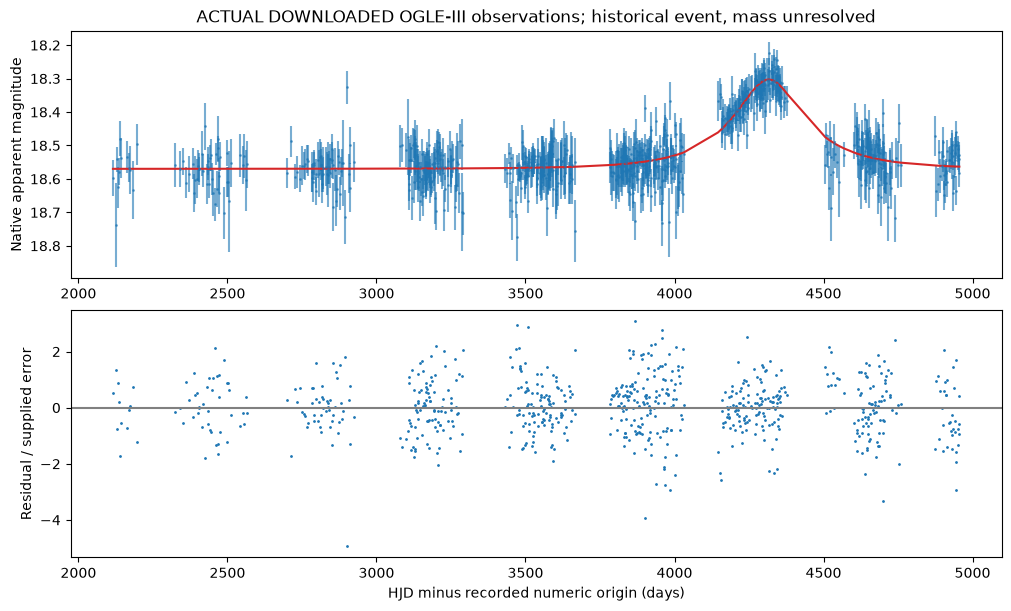

In [3]:
import matplotlib.pyplot as plt
order = np.argsort(dataset.times, kind='stable')
fig, axes = plt.subplots(2, 1, figsize=(10, 6), layout='constrained')
axes[0].errorbar(dataset.times, dataset.magnitudes, yerr=dataset.errors, fmt='.', ms=2, alpha=.6)
axes[0].plot(dataset.times[order], np.asarray(result['predictions_magnitude'])[order], color='tab:red')
axes[0].invert_yaxis()
axes[0].set(ylabel='Native apparent magnitude', title=input_kind)
axes[1].plot(dataset.times, result['standardized_residuals'], '.', ms=2)
axes[1].axhline(0, color='.5')
axes[1].set(xlabel='HJD minus recorded numeric origin (days)', ylabel='Residual / supplied error')
plt.show()

## Export and replay

The ZIP includes the versioned observations, native row IDs and source byte hashes, exact fit controls, results, predictions, residual plot, HTML report and integrity manifest. Its parsed rows are a processed representation; retain the original downloaded files separately. Replay verifies hashes and the likelihood protocol before refitting outside the original file location.

In [4]:
run = Path('user_runs/notebook_unresolved')
run.mkdir(parents=True, exist_ok=True)
bundle = run / 'analysis.zip'
bundle.write_bytes(export_analysis_bundle(result))
check = replay_analysis(bundle, run / 'replayed')
assert check['passed'] and check['same_native_row_identities_and_order']
print(check)
print(result['bhsm_interpretation']['one_potential_rule'])

{'passed': True, 'maximum_prediction_difference_in_supplied_sigma': 0.0, 'tolerance_in_supplied_sigma': 0.001, 'same_status': True, 'same_native_row_identities_and_order': True, 'same_unresolved_quantities': True, 'original_version': '0.2.0rc4', 'current_version': '0.2.0rc4', 'same_package_content': True, 'same_interpretation': True}
Equivalent ordinary-gravity and BHSM envelope descriptions represent the same fitted lens potential and are counted once. A separately derived response is added only when it is a distinct term of the same physical model.


The identified photometric quantities are model-conditional peak time, crossing timescale, absolute impact parameter and instrument brightness/blend combinations when supported by rank, profiles and residuals. Since $t_E=\theta_E/\mu_{rel}$ and $\theta_E^2=\kappa M\pi_{rel}$, photometry alone leaves mass, distance, angular proper motion, horizon and core state unavailable. A validated angular Einstein radius and parallax, with their degeneracies and systematics, are needed for a mass inference. The optional HST importer preserves native rows but blocks precision inference when timing/frame metadata are unresolved.